# E3 · Reconfigure by gating
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

Switch springs on and off, even mid-run, and keep predicting with no refit.

**Where we're at.** Step 1, rung 1. Transfer across body counts works inside the training graph frequencies (E2).

**Where the system is after the last experiments.** Stars and complete graphs, whose graph frequencies lie outside the training range, transfer about 6× worse.

**Where we want it.** Springs switched on and off, even mid-run, with no refit.

**How this set moves it.** Fits on half of the 32 gate patterns of a ring of 5, predicts the other half, and cuts a spring halfway through a run.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e3")
world = config.world_from(cfg)
p = cfg["e3"]

In [2]:
F.ledger("e3")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | ring | how the springs are wired |
| `n` | 5 | number of bodies |
| `seen` | 16 | gate patterns used for fitting |
| `trajectories` | 5 | trajectories per run |
| `steps` | 200 | steps per trajectory |
| `test_trajectories` | 5 | trajectories per test |
| `kappas` | [1.0, 4.0] | spring stiffnesses swept (1/s²) |
| `amplitude` | 0.1 | starting swing size (rad) |
| `switch_step` | 100 | step at which a spring is cut |
| `switch_edge` | 0 | spring cut at the switch |

## The question

The step is linear in the gates, one spring at a time:

$$L(g) = \delta^\top \operatorname{diag}(g)\,\delta = \sum_e g_e\,\underbrace{b_e b_e^\top}_{\text{spring } e\text{'s own Laplacian}}$$

so a model fitted on some patterns has nothing pattern-specific to forget. Cutting a stretched spring removes its energy $\tfrac{\kappa}{2}(\theta_v-\theta_u)^2$: a real jump in the world, not a model error.

**Prediction.** Held-out patterns are predicted as well as seen ones, and the deviation does not jump when a spring is cut.
**Pass if** held-out deviations, and the deviation just after the cut, are within 1.5× of their references.

In [3]:
runs = F.ensure_results("e3")

e3: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:52+00:00)


## The world: a ring of 5, before and after the cut

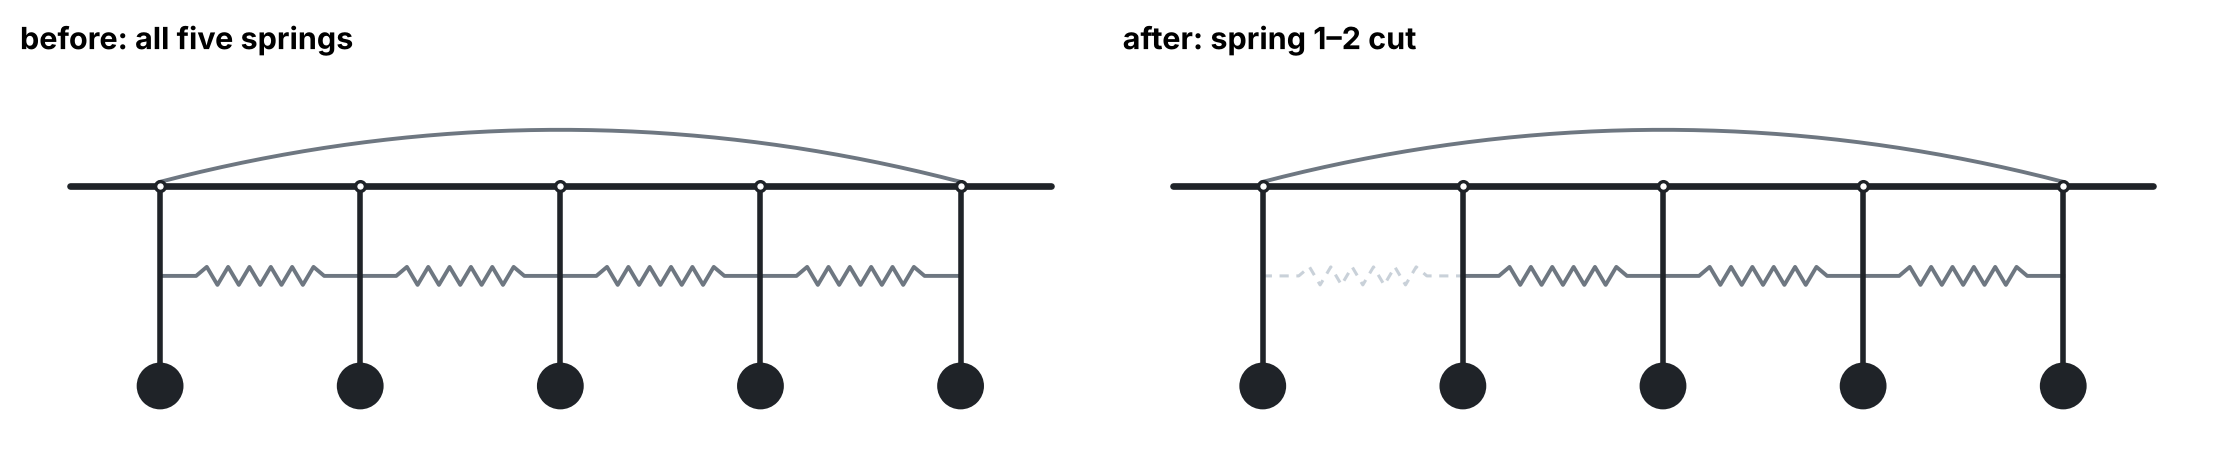

In [4]:
e = graphs.ring(5)
g_off = np.ones(5); g_off[p["switch_edge"]] = 0
F.schematics([("before: all five springs", 5, e, None), ("after: spring 1–2 cut", 5, e, g_off)], cols=2);

## Nominal vs actual: cutting a spring at 5 s, κ = 4

Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time. The spring between bodies 1 and 2 turns dashed at the cut; the model swaps $L(g)$ at the same moment.

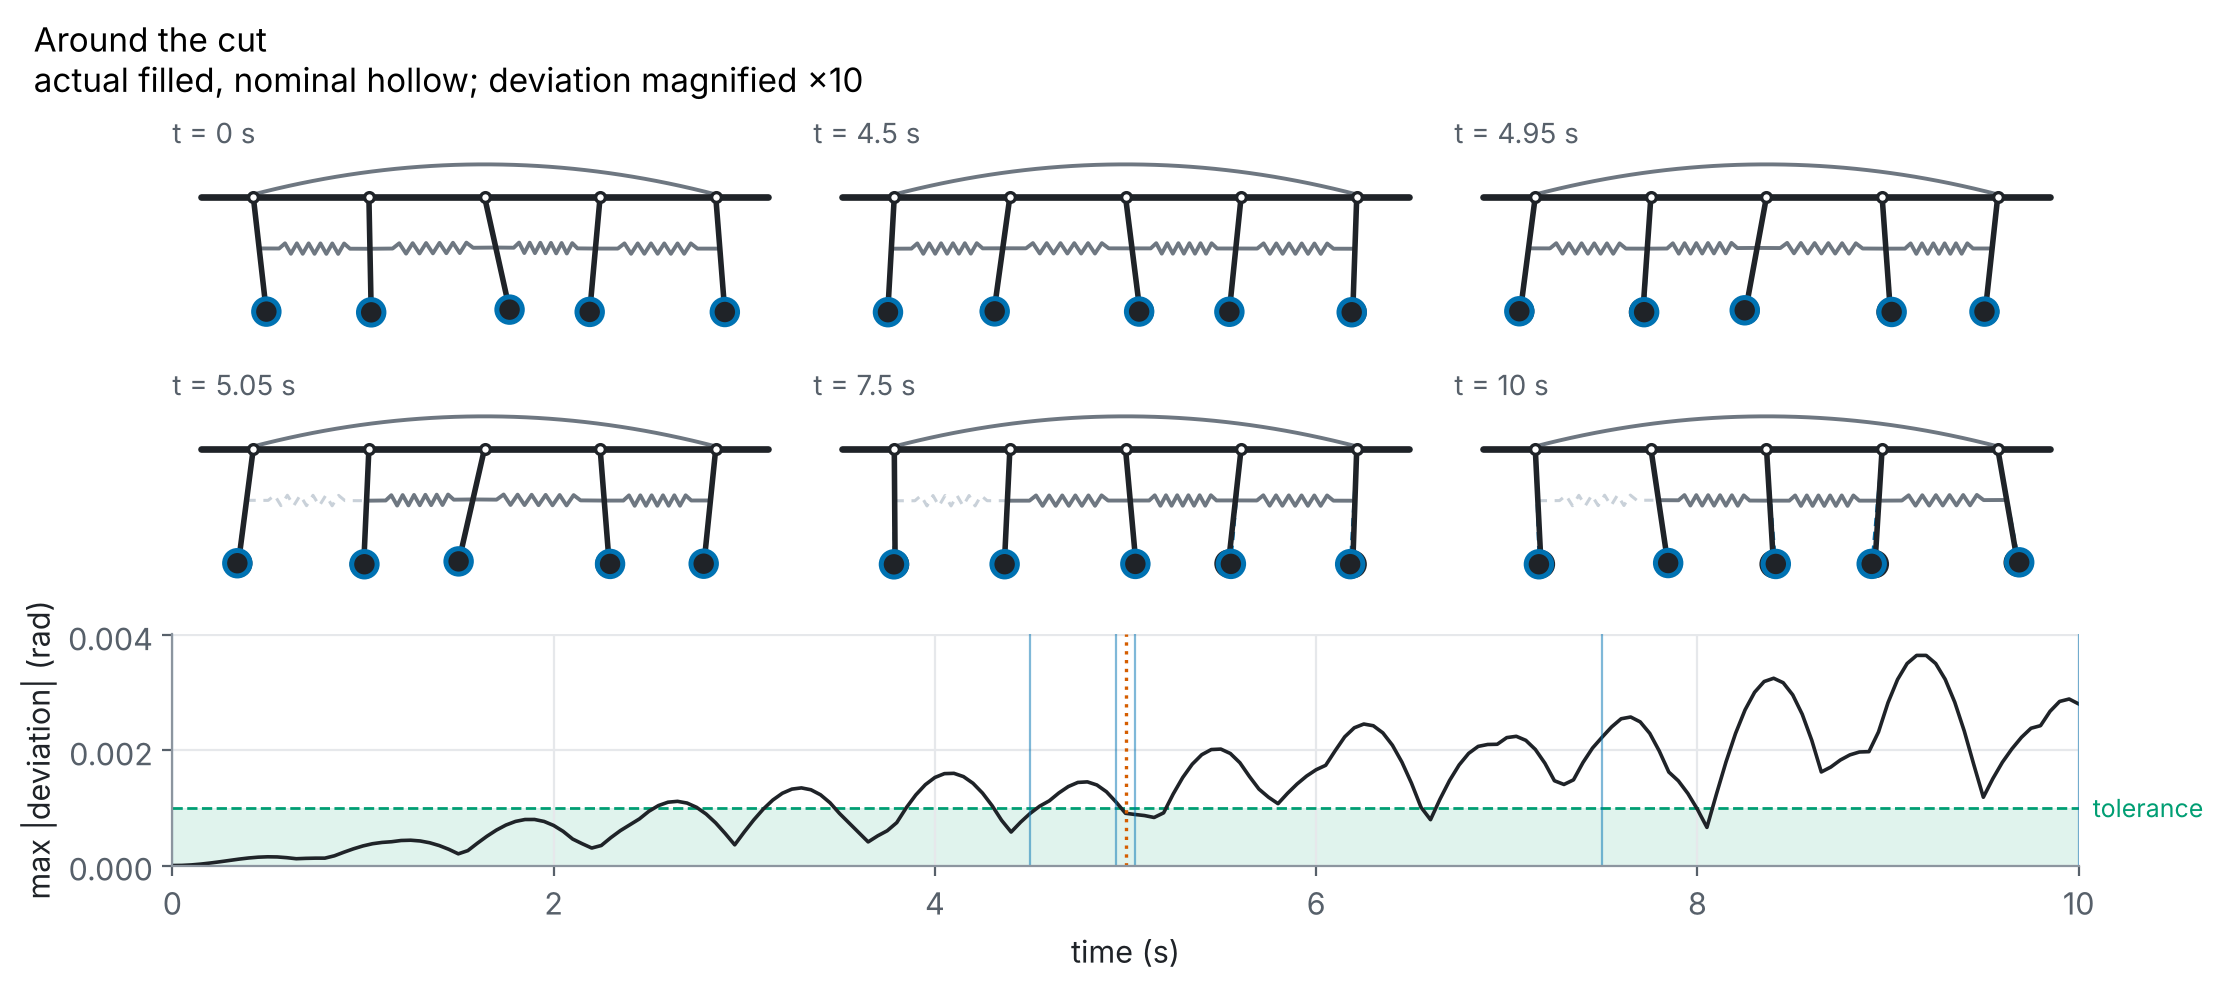

In [5]:
a = runs[0]["arrays"]
tol = 0.01 * p["amplitude"]
display(viz.player(a["switch_act_k4"], a["switch_nom_k4"], graphs.ring(5), a["switch_gates_k4"], dt=world.dt, tol=tol,
                   switch_steps=[p["switch_step"]], title="Ring of 5, κ = 4: spring 1–2 cut at 5 s",
                   subtitle="Free-running prediction for 10 s; tolerance 1% of the swing."))
viz.film_strip(a["switch_act_k4"], a["switch_nom_k4"], graphs.ring(5), a["switch_gates_k4"], dt=world.dt, tol=tol,
               times=[0, 4.5, 4.95, 5.05, 7.5, 10], switch_steps=[p["switch_step"]],
               title="Around the cut");

## Seen and unseen patterns

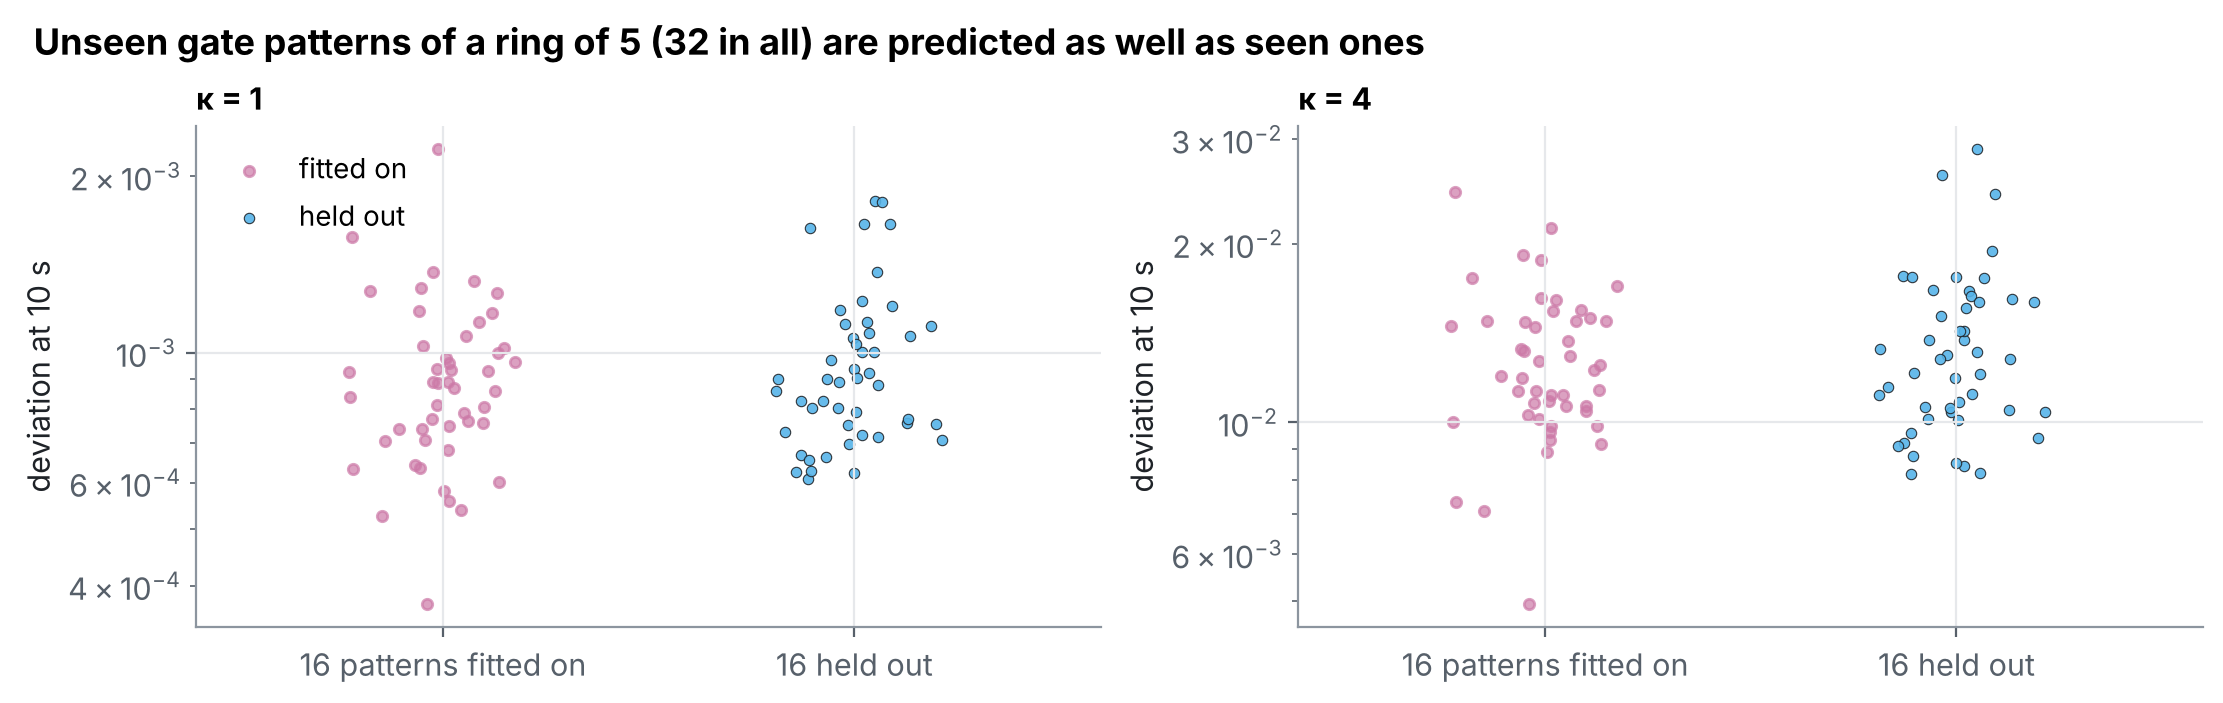

In [6]:
F.e3_patterns(runs);

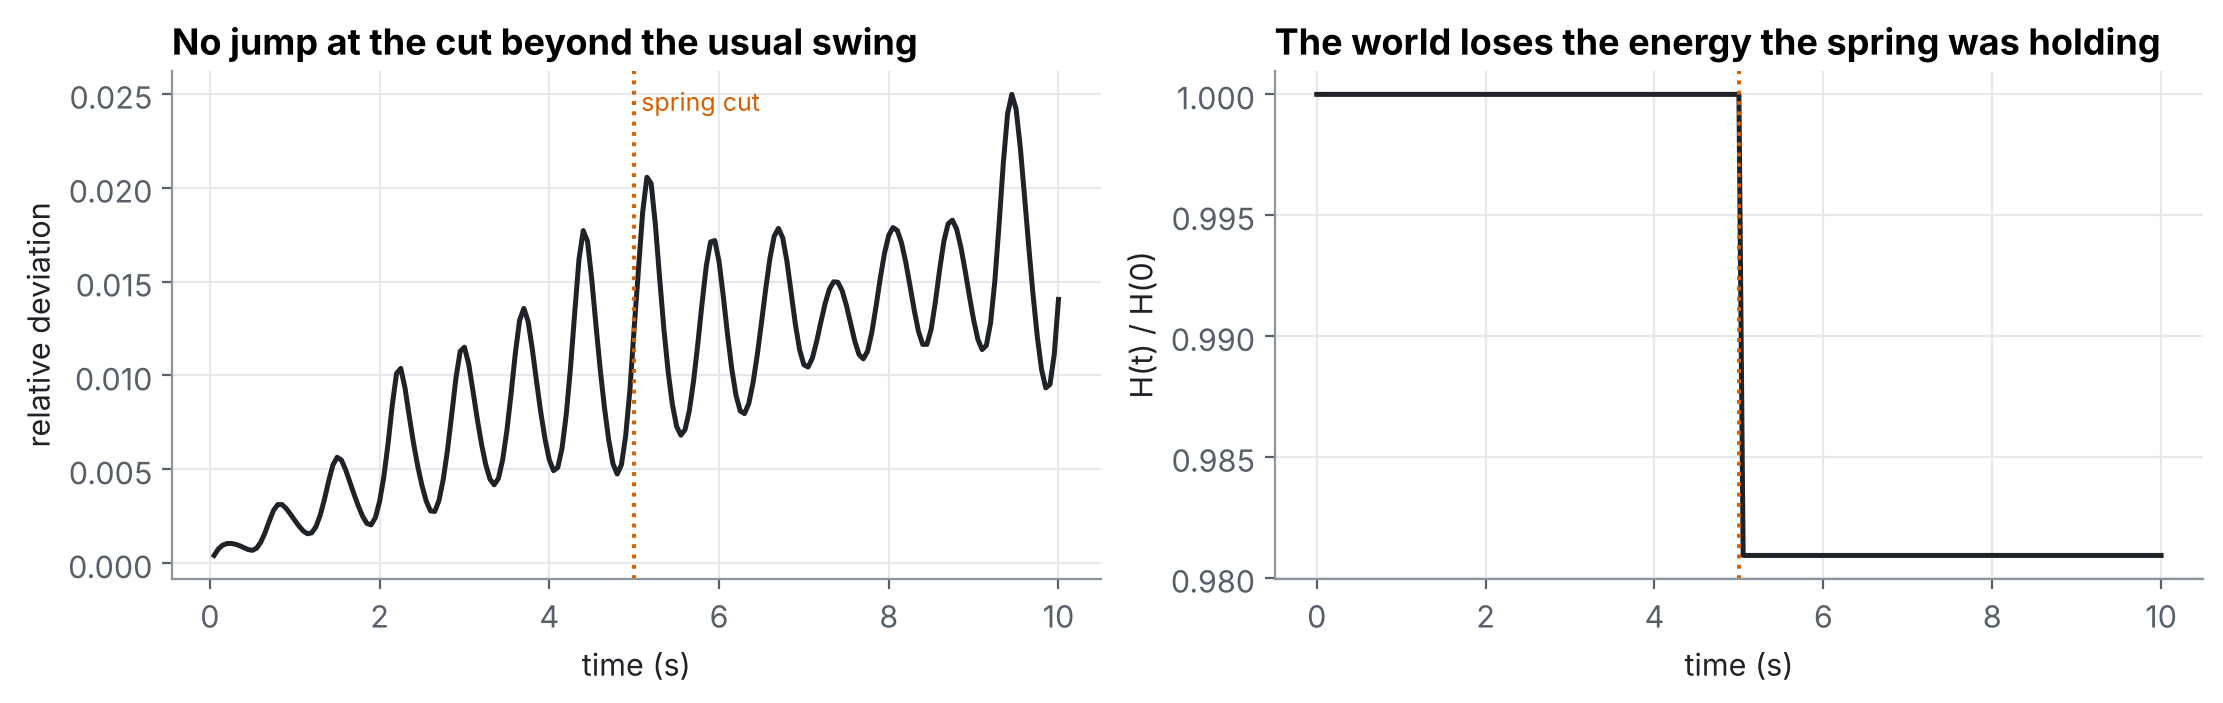

In [7]:
F.e3_switch(runs[0], 4.0, world, p['switch_step']);

In [8]:
b = lambda k, key: [r["metrics"]["by_kappa"][k][key] for r in runs]
sw = lambda k, key: [r["metrics"]["by_kappa"][k]["switch"][key] for r in runs]
F.say(f"At κ = 1, held-out patterns deviate by {F.spread(b('1', 'held_rollout'))} at 10 s against "
      f"{F.spread(b('1', 'seen_rollout'))} for seen ones. Cutting a spring changes the world's energy by "
      f"{F.spread([100 * x for x in b('4', 'energy_jump_mean')])}% at κ = 4, while the model's deviation goes from "
      f"{F.spread(sw('4', 'before'))} just before the cut to {F.spread(sw('4', 'just_after'))} just after.")

> **Finding.** At κ = 1, held-out patterns deviate by 9.68 × 10⁻⁴ (9.39 × 10⁻⁴ to 9.98 × 10⁻⁴) at 10 s against 9.14 × 10⁻⁴ (8.82 × 10⁻⁴ to 9.60 × 10⁻⁴) for seen ones. Cutting a spring changes the world's energy by −7.5 (−8.86 to −5.4)% at κ = 4, while the model's deviation goes from 0.0118 (0.0113 to 0.0125) just before the cut to 0.0145 (0.0137 to 0.0156) just after.

## Inspection report

In [9]:
rows = []
for k in ("1", "4"):
    held = np.mean(b(k, "held_rollout")) / np.mean(b(k, "seen_rollout"))
    jump = np.mean(sw(k, "just_after")) / np.mean(sw(k, "before"))
    rows += [{"characteristic": f"κ = {k}: held-out ÷ seen deviation at 10 s", "nominal": held, "actual": 1.0,
              "deviation": held - 1, "tolerance": 0.5},
             {"characteristic": f"κ = {k}: deviation just after ÷ just before the cut", "nominal": jump, "actual": 1.0,
              "deviation": jump - 1, "tolerance": 0.5},
             {"characteristic": f"κ = {k}: world's energy change at the cut (physics)",
              "actual": viz.pct(float(np.mean(b(k, "energy_jump_mean")))), "status": None}]
viz.inspection_report(rows, title="Reconfiguration, means over seeds")

**Reconfiguration, means over seeds**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| κ = 1: held-out ÷ seen deviation at 10 s | 1.058 | 1 | 0.05835 | ±0.5 | ✓ **in** |
| κ = 1: deviation just after ÷ just before the cut | 0.9517 | 1 | −0.04827 | ±0.5 | ✓ **in** |
| κ = 1: world's energy change at the cut (physics) | — | −3.1% | — | — | — |
| κ = 4: held-out ÷ seen deviation at 10 s | 1.059 | 1 | 0.05919 | ±0.5 | ✓ **in** |
| κ = 4: deviation just after ÷ just before the cut | 1.232 | 1 | 0.2323 | ±0.5 | ✓ **in** |
| κ = 4: world's energy change at the cut (physics) | — | −7.5% | — | — | — |

## Log

In [10]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:52+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:28:53+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:28:53+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |